# Pulmonary pulse-wave network with Windkessel outlets: active subspaces of main pulmonary artery pulse pressure

Data and model from: **Mitchel J. Colebank**, "Assessing parameter identifiability of a hemodynamics PDE
model using spectral surrogates and dimension reduction", *PLOS Computational Biology* 21(10): e1013553
(2025), [doi:10.1371/journal.pcbi.1013553](https://doi.org/10.1371/journal.pcbi.1013553).

Department of Mathematics, University of South Carolina, Columbia, South Carolina, United States of America;
Department of Biomedical Engineering, University of South Carolina, Columbia, South Carolina, United States
of America.

Notebook: Claude (Anthropic) for P. Constantine, 2026

## Summary

The 1-D pulmonary artery model of Colebank (2025) with Windkessel outlets has nine inputs: three
wall-stiffness coefficients and a proximal resistance, distal resistance and compliance at each of the two
outlets; new runs of the author's solver at 160 Latin hypercube points, with finite-difference gradients, give
the systolic, diastolic and mean pressure at the midpoint of the main pulmonary artery. The pulse pressure
(systolic minus diastolic) has a one-dimensional active subspace ($\lambda_1/\lambda_2 = 9.4$) led by the wall
stiffness offset $k_3$, with smaller contributions from the proximal resistances and the compliances, and the
systolic pressure is close to one-dimensional along a direction that mixes $k_3$ with all four resistances. The
mean pressure is a control case: it equals the mean inflow times the parallel outlet resistance, so its
subspace is two-dimensional to within $10^{-6}$ of $\lambda_1$ and carries no information about the
walls or the compliances.

## Active subspaces in brief

For a scalar function $f(\mathbf{x})$ of $m$ inputs scaled to $[-1,1]^m$ with a uniform density, the matrix
$C = \mathbb{E}[\nabla f\,\nabla f^\top] = W\Lambda W^\top$ is estimated from sampled gradients. A large gap
after the $n$-th eigenvalue means that $f$ changes mostly along the first $n$ eigenvectors $W_1$, so
$f(\mathbf{x}) \approx g(W_1^\top \mathbf{x})$ with $n < m$ active variables; a sufficient summary plot of
$f$ against $W_1^\top\mathbf{x}$ shows it. See P. G. Constantine, *Active Subspaces: Emerging Ideas for
Dimension Reduction in Parameter Studies*, SIAM (2015),
[doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

## The model

**Network and equations.** The model is a 1-D pulse-wave model of the main, left and right pulmonary
arteries (MPA, LPA, RPA; paper p. 4) with a prescribed inflow time series at the MPA inlet. Mass and momentum
balance (paper Eqs. 1-2, p. 3):

$$\frac{\partial A}{\partial t} + \frac{\partial q}{\partial x} = 0, \qquad
\frac{\partial q}{\partial t} + \frac{\gamma+2}{\gamma+1}\frac{\partial}{\partial x}\left(\frac{q^2}{A}\right)
+ \frac{A}{\rho}\frac{\partial p}{\partial x} = -\frac{2\pi\mu(\gamma+2)}{\rho}\frac{q}{A},$$

with a power-law velocity profile, $\gamma = 9$ (Eq. 3), and the linear wall model (Eq. 4, p. 3)

$$p = \frac{4}{3}\frac{Eh}{r_0}\left(\sqrt{\frac{A}{A_0}} - 1\right), \qquad \frac{Eh}{r_0} = k_1 e^{-k_2 r_0} + k_3 .$$

Each terminal vessel ends in a three-element Windkessel. The paper's Eq. 5 (p. 4) prints
$\frac{dp}{dt} = R_p\left(\frac{dq}{dt}\right) + q\left(\frac{R_p+R_d}{R_pR_d}\right) - \frac{p}{R_dC_T}$;
its middle term is not dimensionally consistent. Fig. 1 on the same page prints the standard form, used
here: $\frac{dp}{dt} - R_p\frac{dq}{dt} = q\,\frac{R_p + R_d}{R_d C_T} - \frac{p}{R_d C_T}$. The solver is the authors' two-step
Lax-Wendroff code `sor06` (paper p. 4), run here at its pinned commit; it repeats cardiac cycles
(period 0.9 s) until two successive cycles of inlet pressure differ by a squared sum below $10^{-5}$ and
prints one more cycle at 512 time points.

**Notes on the printed model.** (i) The paper writes $k_1 e^{-k_2 r_0}$ (Eq. 4); the code computes
$k_1 e^{k_2 r_0}$ with $k_2 \in [-30, -10]$ cm$^{-1}$, the same law with the opposite sign of $k_2$. This
notebook uses the code's $k_2$. (ii) The paper gives $k_1, k_3$ in mmHg, $R$ in mmHg s/mL and $C_T$ in
mL/mmHg (p. 4). In the code, $k_1, k_3$ are in g/(cm s$^2$) and $R_p, R_d, C_T$ are in the solver's
nondimensional units, 1 unit of $R$ = 0.0776 mmHg s/mL and 1 unit of $C_T$ = 1.288 mL/mmHg (printed
below). (iii) The parameter set of Eq. 6 (p. 4) lists $R_{p,2}$ twice; the ninth parameter is $R_{d,2}$.

**Inputs.** The paper does not print the ranges in its main text; they are taken from the authors' sampling
script (`WK_Simulator/sample_3ves.m`), which draws a Latin hypercube (`lhsdesign`) on these bounds with $k_1$
and $k_3$ log-uniform. The paper states uniform priors on all parameters (p. 5); the code's log-uniform
$k_1, k_3$ is followed here, so the inputs of this notebook are $(\ln k_1, k_2, \ln k_3, R_{p,1}, R_{p,2},
R_{d,1}, R_{d,2}, C_{T,1}, C_{T,2})$, each uniform on its interval. Subscript 1 is the LPA, 2 the RPA (p. 5).

**Quantities of interest (this data set's choice).** The paper emulates whole time series (PCA scores of the
midpoint pressure, flow and area signals, p. 6). This data set uses scalars of the MPA midpoint pressure
over the printed cycle, in mmHg: its maximum $p_{sys}$, its minimum $p_{dia}$ and its time average $\bar p$
are stored. The main QoI is the **pulse pressure** $PP = p_{sys} - p_{dia}$, computed in the notebook
from the stored values, with gradient $\nabla p_{sys} - \nabla p_{dia}$. The systolic pressure is the
second QoI. The mean pressure is kept as a short control section: it is fixed by the outlet resistances
alone (Ohm's law for the mean flow), so its subspace says nothing about the wave dynamics.

**Data.** 160 Latin hypercube points (seed 2025130) with forward-difference gradients (step $10^{-3}$ of each
half-range; 9 extra solver runs per point), generated here with the authors' solver; see DATA.md.

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac
import pulmonary_wk_driver as D   # names, bounds and unit factors (numpy only); running needs g++

SEED = 2025                        # the only seed in this notebook (bootstrap)
t_start = time.perf_counter()
warnings.filterwarnings('ignore', category=ac.ActiveSubspacesWarning)
lab = [r'$\ln k_1$', r'$k_2$', r'$\ln k_3$', r'$R_{p,1}$', r'$R_{p,2}$', r'$R_{d,1}$', r'$R_{d,2}$',
       r'$C_{T,1}$', r'$C_{T,2}$']

In [2]:
print(f"{'input':6s} {'units':16s} {'lower':>10s} {'upper':>10s}   physical range")
for j, (n, u, lo, up) in enumerate(zip(D.NAMES, D.UNITS, D.LOWER, D.UPPER)):
    if j in (0, 2):
        phys = f'k = {np.exp(lo):.3g} to {np.exp(up):.3g} g/(cm s^2) = {np.exp(lo) * D.K_TO_MMHG:.4g} to {np.exp(up) * D.K_TO_MMHG:.4g} mmHg'
    elif j == 1:
        phys = 'per cm (code sign: Eh/r0 = k1 exp(k2 r0) + k3)'
    elif j < 7:
        phys = f'{lo * D.R_SCALE:.4g} to {up * D.R_SCALE:.4g} mmHg s/mL'
    else:
        phys = f'{lo * D.C_SCALE:.3g} to {up * D.C_SCALE:.4g} mL/mmHg'
    print(f'{n:6s} {u:16s} {lo:10.4g} {up:10.4g}   {phys}')
print(f'\nunit factors: R {D.R_SCALE:.5f} mmHg s/mL, C_T {D.C_SCALE:.5f} mL/mmHg per solver unit; m = {len(D.NAMES)}')

input  units                 lower      upper   physical range
ln_k1  ln(g/(cm s^2))        13.82      18.42   k = 1e+06 to 1e+08 g/(cm s^2) = 750.1 to 7.501e+04 mmHg
k2     1/cm                    -30        -10   per cm (code sign: Eh/r0 = k1 exp(k2 r0) + k3)
ln_k3  ln(g/(cm s^2))        10.31      13.12   k = 3e+04 to 5e+05 g/(cm s^2) = 22.5 to 375 mmHg
Rp1    nondim                  0.5         10   0.03881 to 0.7763 mmHg s/mL
Rp2    nondim                  0.5         10   0.03881 to 0.7763 mmHg s/mL
Rd1    nondim                  0.8         20   0.0621 to 1.553 mmHg s/mL
Rd2    nondim                  0.8         20   0.0621 to 1.553 mmHg s/mL
CT1    nondim                1e-05        1.2   1.29e-05 to 1.546 mL/mmHg
CT2    nondim                1e-05        1.2   1.29e-05 to 1.546 mL/mmHg

unit factors: R 0.07763 mmHg s/mL, C_T 1.28819 mL/mmHg per solver unit; m = 9


## Load the data

In [3]:
X = np.loadtxt('inputs.csv', delimiter=',')            # (160, 9) code-unit inputs, D.NAMES order
F = np.loadtxt('outputs.csv', delimiter=',')           # (160, 4) p_mean, p_sys, p_dia [mmHg], status
G = np.loadtxt('gradients.csv', delimiter=',')         # (160, 27) d(p_mean, p_sys, p_dia)/dx_j
for n, a in [('X', X), ('F', F), ('G', G)]:
    print(f'{n} {a.shape}')

X (160, 9)
F (160, 4)
G (160, 27)


In [4]:
status = F[:, 3].astype(int)
print('status counts:', {s: int(np.sum(status == s)) for s in range(4)})
keep = status <= 1          # rule: drop rows whose base run (2) or a perturbed run (3) failed
Xk = X[keep]
Gk = G[keep].reshape(-1, 3, 9)                            # [row, stored QoI, input]
hw = 0.5 * (D.UPPER - D.LOWER)
Z = 2 * (Xk - D.LOWER) / (D.UPPER - D.LOWER) - 1
print(f'rows kept: {keep.sum()} of {len(X)}; normalized inputs in [{Z.min():.4f}, {Z.max():.4f}]')
U = (X - D.LOWER) / (D.UPPER - D.LOWER)
strata = np.floor(U * len(X)).astype(int)
print('Latin hypercube: every column has one point per stratum:',
      all(len(np.unique(strata[:, j])) == len(X) for j in range(9)))
# QoIs: pulse pressure (computed here), systolic, diastolic, mean
QF = {'pp': F[keep, 1] - F[keep, 2], 'p_sys': F[keep, 1], 'p_dia': F[keep, 2], 'p_mean': F[keep, 0]}
QG = {'pp': Gk[:, 1] - Gk[:, 2], 'p_sys': Gk[:, 1], 'p_dia': Gk[:, 2], 'p_mean': Gk[:, 0]}
for name, v in QF.items():
    print(f'{name:6s}: min {v.min():6.2f}, median {np.median(v):6.2f}, max {v.max():6.2f} mmHg; sd {v.std(ddof=1):5.2f}')
print(f"correlation of pp with p_mean: {np.corrcoef(QF['pp'], QF['p_mean'])[0, 1]:.3f}; "
      f"with p_sys: {np.corrcoef(QF['pp'], QF['p_sys'])[0, 1]:.3f}")
for i in np.where(~keep)[0]:
    print(f'row {i} (status {status[i]}) inputs:', ', '.join(f'{n} {v:.4g}' for n, v in zip(D.NAMES, X[i])))
print('rows with p_dia < 0 mmHg:', int(np.sum(QF['p_dia'] < 0)), '; rows with p_sys > 100 mmHg:', int(np.sum(QF['p_sys'] > 100)))

status counts: {0: 158, 1: 0, 2: 2, 3: 0}
rows kept: 158 of 160; normalized inputs in [-0.9997, 0.9975]
Latin hypercube: every column has one point per stratum: True
pp    : min   4.49, median  29.23, max  96.33 mmHg; sd 23.40
p_sys : min  21.14, median  70.86, max 146.77 mmHg; sd 23.58
p_dia : min   0.67, median  40.35, max  84.22 mmHg; sd 20.29
p_mean: min  11.40, median  55.77, max  96.90 mmHg; sd 18.63
correlation of pp with p_mean: 0.063; with p_sys: 0.627
row 38 (status 2) inputs: ln_k1 17.93, k2 -26.86, ln_k3 10.46, Rp1 5.525, Rp2 6.677, Rd1 19.45, Rd2 14.34, CT1 0.7414, CT2 0.5838
row 55 (status 2) inputs: ln_k1 14.22, k2 -15.8, ln_k3 10.56, Rp1 7.598, Rp2 4.743, Rd1 16.85, Rd2 18.65, CT1 0.7023, CT2 1.126
rows with p_dia < 0 mmHg: 0 ; rows with p_sys > 100 mmHg: 21


158 of the 160 rows are kept. The two failed base runs (status 2, the solver's "too many cycles": the
100-cycle cap was reached before the cycle-to-cycle tolerance) both have $\ln k_3$ within 0.25 of its lower
bound (soft walls) and large distal resistances; dropping them by the stored flag censors the slowest-converging
corner of the box (2 of 160 here, 30 of 2500 in the paper, p. 10). Every column of the design has one point per
stratum, so the 160 points are a Latin hypercube. All inputs are positive where they must be, so no sample lies
outside physical meaning; the MPA pressure ranges from 0.67 mmHg (lowest $p_{dia}$) to 146.77 mmHg (highest
$p_{sys}$), and 21 rows have $p_{sys}$ above 100 mmHg, which the authors' box allows (their seven training
waveforms in Fig. 3(a), p. 12, span about 20 to 120 mmHg). The pulse pressure ranges from 4.49 to 96.33 mmHg and
is nearly uncorrelated with the mean pressure (correlation 0.063), so it carries information the mean does not.

## Estimate the subspace

Gradients are available at every kept point, so the estimator is the gradient-based one
(`estimator='as'`), $\hat C = \frac{1}{M}\sum_i \nabla f_i \nabla f_i^\top$ in normalized coordinates (each
input scaled by its half-range; the space is `ac.Uniform` on the code-unit bounds, and the physical
gradients are passed as they are). The pulse-pressure gradient is the difference of the stored systolic and
diastolic gradients. Bootstrap with 500 replicates gives the eigenvalue intervals and subspace errors.
Eigenvector signs: the paper shows no eigenvectors, so the rule here is that the mean gradient has a
positive projection on each eigenvector (`ac.orient(by='mean_gradient')`).

In [5]:
space = ac.Uniform(D.LOWER, D.UPPER, names=D.NAMES)
subs = {}
for name in QF:
    s = ac.active_subspace(space=space, X=Xk, f=QF[name], grads=QG[name], estimator='as', n=1,
                           nboot=500, rng=SEED)
    subs[name] = ac.orient(s, by='mean_gradient', grads=QG[name])


def loo(name, n):
    # LOO R^2 of a quadratic in the first n active variables
    s = ac.active_subspace(space=space, X=Xk, f=QF[name], grads=QG[name], estimator='as', n=n)
    return ac.fit_surrogate(X=Xk, f=QF[name], space=space, subspace=s, kind='poly', degree=2).loo_r_squared


sub = subs['pp']
lam = sub.eigenvalues
lo_ci, hi_ci = np.percentile(sub.bootstrap_eigenvalues, [2.5, 97.5], axis=0)
print('pulse pressure eigenvalues (normalized inputs, mmHg^2) with bootstrap 95% intervals:')
for i in range(9):
    print(f'  lambda_{i + 1} = {lam[i]:.3e}  [{lo_ci[i]:.3e}, {hi_ci[i]:.3e}]')
print('ratios lambda_i/lambda_(i+1), i = 1..4:', ', '.join(f'{lam[i] / lam[i + 1]:.1f}' for i in range(4)))
print(f'share of the trace: lambda1 {lam[0] / lam.sum():.3f}, lambda1 + lambda2 {(lam[0] + lam[1]) / lam.sum():.3f}')

pulse pressure eigenvalues (normalized inputs, mmHg^2) with bootstrap 95% intervals:
  lambda_1 = 1.508e+03  [1.303e+03, 1.739e+03]
  lambda_2 = 1.605e+02  [1.196e+02, 2.377e+02]
  lambda_3 = 9.354e+01  [5.218e+01, 1.423e+02]
  lambda_4 = 6.252e+01  [3.146e+01, 7.836e+01]
  lambda_5 = 4.099e+01  [1.936e+01, 5.472e+01]
  lambda_6 = 1.439e+01  [6.807e+00, 2.598e+01]
  lambda_7 = 1.269e+01  [2.967e+00, 1.777e+01]
  lambda_8 = 1.161e-02  [2.350e-03, 2.651e-02]
  lambda_9 = 2.115e-08  [6.673e-09, 3.859e-08]
ratios lambda_i/lambda_(i+1), i = 1..4: 9.4, 1.7, 1.5, 1.5
share of the trace: lambda1 0.797, lambda1 + lambda2 0.882


bootstrap mean subspace distance, k = 1..5: [0.051 0.315 0.452 0.426 0.203]


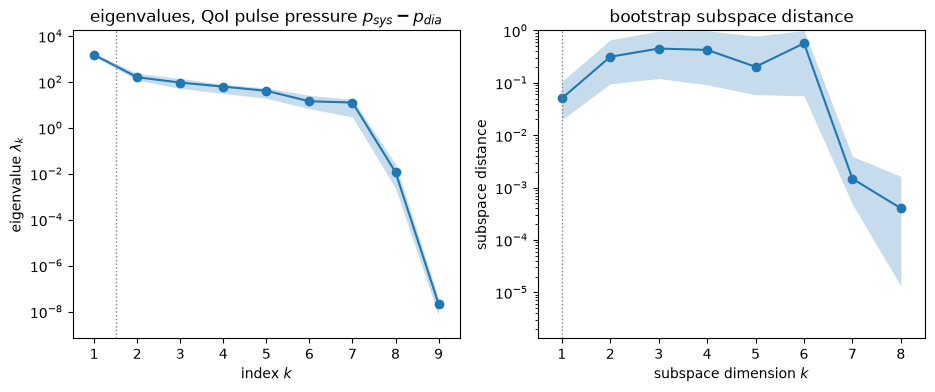

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ac.plotting.plot_eigenvalues(sub, ax=axes[0])
axes[0].set_title(r'eigenvalues, QoI pulse pressure $p_{sys} - p_{dia}$')
ac.plotting.plot_subspace_errors(sub, ax=axes[1])
axes[1].set_title('bootstrap subspace distance')
plt.close(fig)
print('bootstrap mean subspace distance, k = 1..5:',
      np.array2string(sub.bootstrap_distances.mean(axis=0)[:5], precision=3))
fig

The first eigenvalue of the pulse pressure, 1.508e+03 (bootstrap interval [1.303e+03, 1.739e+03]), is 9.4
times the second, 1.605e+02 ([1.196e+02, 2.377e+02]); the next ratios are 1.7, 1.5 and 1.5, so there is one
gap and it is after the first eigenvalue. $\lambda_1$ holds 0.797 of the trace. The bootstrap subspace
distance is 0.051 for $n = 1$ and 0.315 for $n = 2$: the first direction is well determined by 158 points,
and the second is not separated from the third.

w1: ln_k1 +0.000, k2 +0.001, ln_k3 +0.954, Rp1 +0.165, Rp2 +0.158, Rd1 -0.040, Rd2 -0.041, CT1 -0.120, CT2 -0.139
w2: ln_k1 -0.000, k2 -0.001, ln_k3 -0.273, Rp1 +0.559, Rp2 +0.520, Rd1 +0.088, Rd2 +0.157, CT1 -0.193, CT2 -0.522
E[(df/dx_j)^2] / lambda1 (normalized inputs): ln_k1 4.3e-07, k2 7.7e-06, ln_k3 9.2e-01, Rp1 8.5e-02, Rp2 9.0e-02, Rd1 1.1e-02, Rd2 1.4e-02, CT1 4.7e-02, CT2 8.9e-02


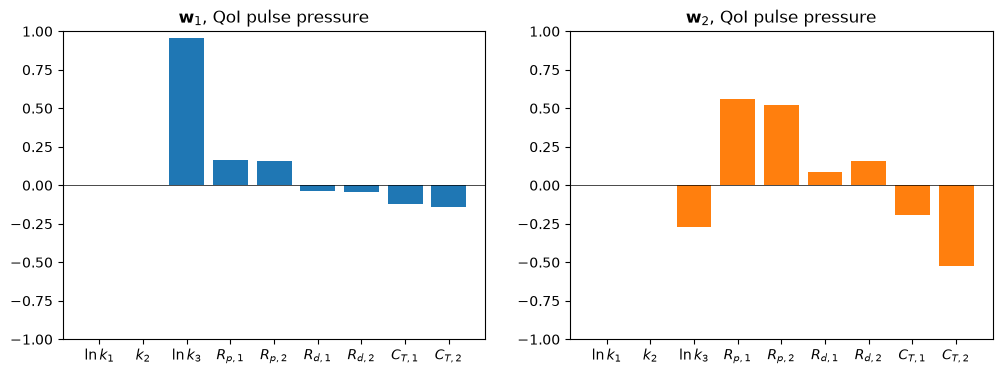

In [7]:
W = sub.W
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for k in range(2):
    axes[k].bar(range(9), W[:, k], color=f'C{k}')
    axes[k].set_xticks(range(9)); axes[k].set_xticklabels(lab)
    axes[k].axhline(0, color='k', lw=.5); axes[k].set_ylim(-1, 1)
    axes[k].set_title(rf'$\mathbf{{w}}_{k + 1}$, QoI pulse pressure')
plt.close(fig)
for k in range(2):
    print(f'w{k + 1}:', ', '.join(f'{n} {W[j, k]:+.3f}' for j, n in enumerate(D.NAMES)))
msq = {name: np.mean((QG[name] * hw)**2, axis=0) / subs[name].eigenvalues[0] for name in QF}
print('E[(df/dx_j)^2] / lambda1 (normalized inputs):', ', '.join(f'{n} {v:.1e}' for n, v in zip(D.NAMES, msq['pp'])))
fig

$\mathbf{w}_1$ of the pulse pressure is dominated by the wall-stiffness offset ($\ln k_3$ +0.954): stiffer walls
raise the wave speed and the pulse pressure. The proximal resistances add to it (Rp1 +0.165, Rp2 +0.158), the
compliances lower it (CT1 −0.120, CT2 −0.139), and the distal resistances enter weakly with a negative sign
(Rd1 −0.040, Rd2 −0.041); the mean squared derivative of $\ln k_3$ is 0.92 of $\lambda_1$. $k_1$ and $k_2$ have
mean squared derivatives of at most 7.7e-06 times $\lambda_1$. $\mathbf{w}_2$ combines the proximal
resistances with $C_{T,2}$ and $\ln k_3$, but it is not well determined (distance 0.315 above).

LOO R^2 of pp: quadratic in y1 0.9147, in (y1, y2) 0.9396, in (y1, y2, y3) 0.9460; quadratic in ln k3 alone 0.8341
correlation of pp with y1: 0.9303


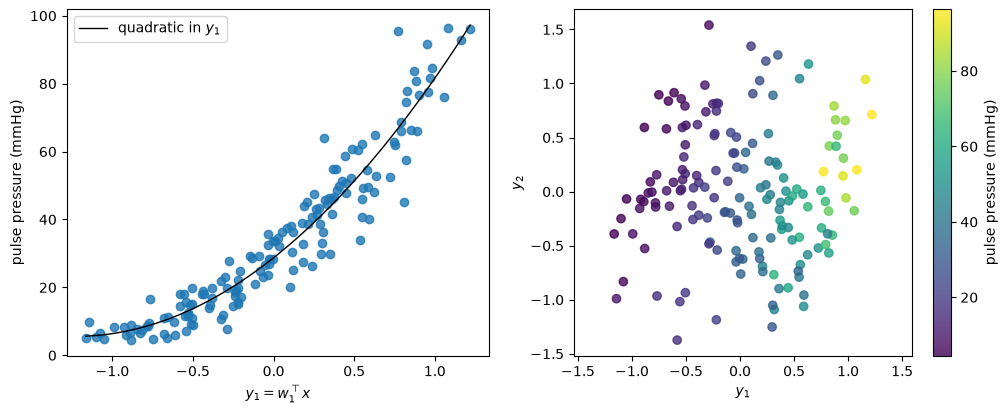

In [8]:
f = QF['pp']
s2 = ac.active_subspace(space=space, X=Xk, f=f, grads=QG['pp'], estimator='as', n=2)
s2 = ac.orient(s2, by='mean_gradient', grads=QG['pp'])
sur1 = ac.fit_surrogate(X=Xk, f=f, space=space, subspace=sub, kind='poly', degree=2)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ac.plotting.plot_sufficient_summary(sub, X=Xk, f=f, dims=1, qoi_label='pulse pressure (mmHg)', ax=axes[0])
y1 = space.to_normalized(Xk) @ W[:, 0]
yy = np.linspace(y1.min(), y1.max(), 200)
axes[0].plot(yy, sur1.evaluate(yy[:, None]), 'k-', lw=1, label='quadratic in $y_1$'); axes[0].legend()
ac.plotting.plot_sufficient_summary(s2, X=Xk, f=f, dims=2, qoi_label='pulse pressure (mmHg)', ax=axes[1])
plt.close(fig)


def loo_poly1(t, v):
    # LOO R^2 of a quadratic in one scalar t, by the hat-matrix formula
    A = np.vstack([np.ones_like(t), t, t * t]).T
    H = A @ np.linalg.solve(A.T @ A, A.T)
    r = (v - H @ v) / (1 - np.diag(H))
    return 1 - r @ r / np.sum((v - v.mean())**2)


z3 = space.to_normalized(Xk)[:, 2]
print(f"LOO R^2 of pp: quadratic in y1 {sur1.loo_r_squared:.4f}, in (y1, y2) {loo('pp', 2):.4f}, "
      f"in (y1, y2, y3) {loo('pp', 3):.4f}; quadratic in ln k3 alone {loo_poly1(z3, f):.4f}")
print(f'correlation of pp with y1: {np.corrcoef(y1, f)[0, 1]:.4f}')
fig

The sufficient summary plot of the pulse pressure against $y_1 = \mathbf{w}_1^\top\mathbf{x}$ is a tight,
gently curved band: a quadratic in $y_1$ has a leave-one-out $R^2$ of 0.9147, and adding $y_2$ and $y_3$
raises it only to 0.9396 and 0.9460. A quadratic in $\ln k_3$ alone reaches 0.8341, so the resistance and
compliance components of $\mathbf{w}_1$ account for part of what one variable explains.

### Systolic pressure

The same estimator on the systolic pressure, with the diastolic pressure printed for completeness (gradients
from the same runs).

p_sys: eigenvalues [1452.928  219.89   107.647   51.784] ...; ratios 6.6, 2.0, 2.1; lambda1 share 0.766, lambda1+2 share 0.882
   w1: ln_k1 +0.000, k2 +0.000, ln_k3 +0.556, Rp1 +0.352, Rp2 +0.359, Rd1 +0.459, Rd2 +0.469, CT1 -0.053, CT2 -0.070
   w2: ln_k1 +0.000, k2 +0.000, ln_k3 -0.101, Rp1 -0.315, Rp2 +0.433, Rd1 -0.586, Rd2 +0.599, CT1 +0.011, CT2 -0.010
   E[(df/dx_j)^2] / lambda1: ln_k1 1.2e-07, k2 2.1e-06, ln_k3 3.6e-01, Rp1 1.6e-01, Rp2 1.7e-01, Rd1 2.8e-01, Rd2 2.8e-01, CT1 1.5e-02, CT2 3.9e-02
   bootstrap mean subspace distance k = 1..3: [0.052 0.124 0.228]; LOO R^2 quadratic in y1 0.9146, in (y1, y2) 0.9522
p_dia: eigenvalues [1078.965  227.626   37.085   22.602] ...; ratios 4.7, 6.1, 1.6; lambda1 share 0.777, lambda1+2 share 0.941
   w1: ln_k1 -0.000, k2 -0.000, ln_k3 -0.428, Rp1 +0.217, Rp2 +0.215, Rd1 +0.600, Rd2 +0.596, CT1 +0.061, CT2 +0.058
   w2: ln_k1 -0.000, k2 -0.000, ln_k3 +0.006, Rp1 -0.308, Rp2 +0.289, Rd1 -0.634, Rd2 +0.648, CT1 +0.019, CT2 -0.003
   E[(df/dx_

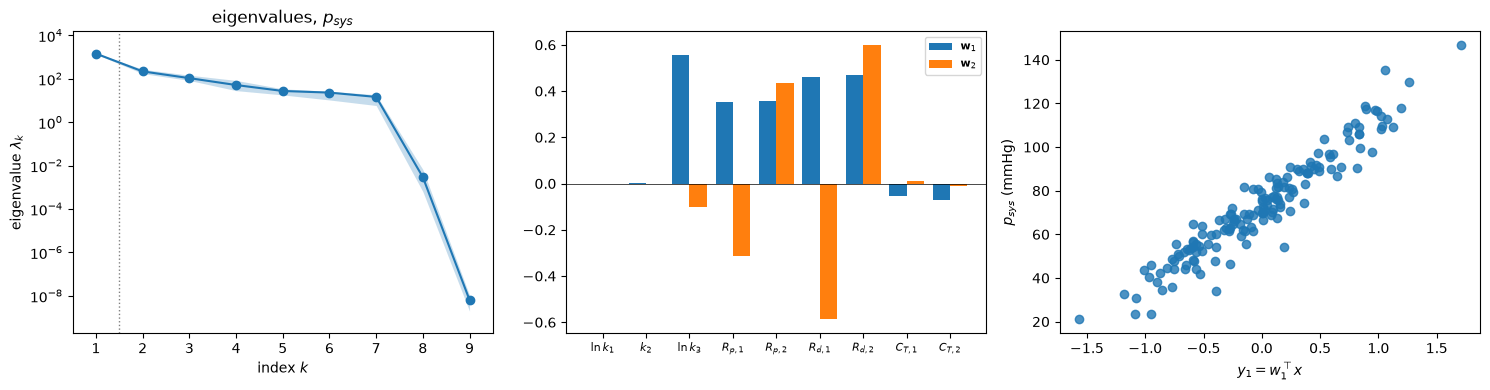

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
s = subs['p_sys']
l_ = s.eigenvalues
sur = ac.fit_surrogate(X=Xk, f=QF['p_sys'], space=space, subspace=s, kind='poly', degree=2)
for name in ('p_sys', 'p_dia'):
    ln = subs[name].eigenvalues
    print(f'{name}: eigenvalues {np.array2string(ln[:4], precision=3)} ...; ratios '
          + ', '.join(f'{ln[i] / ln[i + 1]:.1f}' for i in range(3))
          + f'; lambda1 share {ln[0] / ln.sum():.3f}, lambda1+2 share {(ln[0] + ln[1]) / ln.sum():.3f}')
    print(f'   w1: ' + ', '.join(f'{n} {subs[name].W[j, 0]:+.3f}' for j, n in enumerate(D.NAMES)))
    print(f'   w2: ' + ', '.join(f'{n} {subs[name].W[j, 1]:+.3f}' for j, n in enumerate(D.NAMES)))
    print('   E[(df/dx_j)^2] / lambda1: ' + ', '.join(f'{n} {v:.1e}' for n, v in zip(D.NAMES, msq[name])))
    print(f'   bootstrap mean subspace distance k = 1..3: '
          + np.array2string(subs[name].bootstrap_distances.mean(axis=0)[:3], precision=3)
          + f'; LOO R^2 quadratic in y1 {loo(name, 1):.4f}, in (y1, y2) {loo(name, 2):.4f}')
ac.plotting.plot_eigenvalues(s, ax=axes[0]); axes[0].set_title(r'eigenvalues, $p_{sys}$')
axes[1].bar(range(9), s.W[:, 0], color='C0', width=.4, label=r'$\mathbf{w}_1$')
axes[1].bar(np.arange(9) + .4, s.W[:, 1], color='C1', width=.4, label=r'$\mathbf{w}_2$')
axes[1].set_xticks(np.arange(9) + .2); axes[1].set_xticklabels(lab, fontsize=8)
axes[1].axhline(0, color='k', lw=.5); axes[1].legend(fontsize=8)
ac.plotting.plot_sufficient_summary(s, X=Xk, f=QF['p_sys'], dims=1, qoi_label=r'$p_{sys}$ (mmHg)', ax=axes[2])
plt.tight_layout(); plt.close(fig)
fig

For $p_{sys}$ the ratios are 6.6, 2.0 and 2.1, $\lambda_1$ holds 0.766 of the trace, and the bootstrap
distance is 0.052 at $n = 1$ and 0.124 at $n = 2$. $\mathbf{w}_1$ is the most mixed direction in this data set:
$\ln k_3$ +0.556 together with all four resistances (+0.352 to +0.469) and small negative compliance weights
(−0.053, −0.070). A quadratic in $y_1$ has LOO $R^2$ 0.9146 and one in $(y_1, y_2)$ 0.9522; $\mathbf{w}_2$ is a
left-right contrast of the resistances. The diastolic pressure has ratios 4.7 and 6.1 (comparable, so two
directions), with $\ln k_3$ entering $\mathbf{w}_1$ with the opposite sign (−0.428); that sign difference is why
the pulse pressure isolates $k_3$.

### Mean pressure: a structural control

Over a converged cycle the compliances and the vessel walls store no net volume, so the mean pressure is the
mean inflow times the parallel outlet resistance, $\bar p \approx \bar Q\,(R_{LPA}\,\|\,R_{RPA})$ with
$R = R_p + R_d$. It depends on the inputs only through $R_{p,1}+R_{d,1}$ and $R_{p,2}+R_{d,2}$, so its
two-dimensional subspace is set by this algebra and by the half-ranges of the resistances, not by the PDE.

p_mean eigenvalues: [9.492e+02 2.367e+02 6.696e-04 3.541e-05] ...; ratios 4.01, 3.54e+05, 18.9; lambda3/lambda1 7.1e-07
bootstrap mean subspace distance k = 1..3: 5.1e-02, 1.3e-04, 3.9e-02
E[(df/dx_j)^2] / lambda1: ln_k1 9.4e-13, k2 1.6e-11, ln_k3 7.6e-07, Rp1 1.2e-01, Rp2 1.3e-01, Rd1 4.9e-01, Rd2 5.1e-01, CT1 3.2e-08, CT2 3.6e-08
w1: ln_k1 +0.000, k2 +0.000, ln_k3 +0.000, Rp1 +0.308, Rp2 +0.319, Rd1 +0.622, Rd2 +0.645, CT1 +0.000, CT2 +0.000
w2: ln_k1 +0.000, k2 +0.000, ln_k3 -0.000, Rp1 +0.319, Rp2 -0.308, Rd1 +0.645, Rd2 -0.622, CT1 -0.000, CT2 +0.000
LOO R^2 of p_mean: quadratic in y1 0.9180, in (y1, y2) 0.9956
p_mean against R_LPA || R_RPA (mmHg s/mL): slope 97.23 mL/s, intercept -0.01 mmHg, correlation 1.0000
distance between span(w1, w2) and the two resistance-sum directions: 3.8e-04
Rp:Rd component ratio in w1 0.4947 and 0.4949; half-range ratio 0.4948
d p_mean / d ln k3 (normalized): negative in 0.46 of rows, quartiles [-0.009, 0.025] mmHg


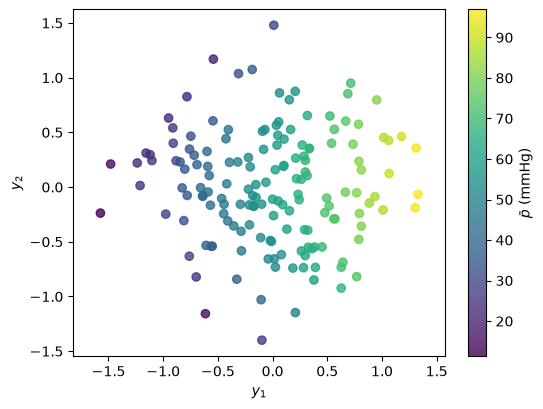

In [10]:
sm = subs['p_mean']
lm = sm.eigenvalues
fm = QF['p_mean']
print('p_mean eigenvalues:', np.array2string(lm[:4], precision=3), '...; ratios '
      + ', '.join(f'{lm[i] / lm[i + 1]:.3g}' for i in range(3)) + f'; lambda3/lambda1 {lm[2] / lm[0]:.1e}')
print('bootstrap mean subspace distance k = 1..3:', ', '.join(f'{v:.1e}' for v in sm.bootstrap_distances.mean(axis=0)[:3]))
print('E[(df/dx_j)^2] / lambda1:', ', '.join(f'{n} {v:.1e}' for n, v in zip(D.NAMES, msq['p_mean'])))
for k in range(2):
    print(f'w{k + 1}:', ', '.join(f'{n} {sm.W[j, k]:+.3f}' for j, n in enumerate(D.NAMES)))
print(f"LOO R^2 of p_mean: quadratic in y1 {loo('p_mean', 1):.4f}, in (y1, y2) {loo('p_mean', 2):.4f}")
R1 = (Xk[:, 3] + Xk[:, 5]) * D.R_SCALE
R2 = (Xk[:, 4] + Xk[:, 6]) * D.R_SCALE
Rpar = R1 * R2 / (R1 + R2)
c = np.polyfit(Rpar, fm, 1)
print(f'p_mean against R_LPA || R_RPA (mmHg s/mL): slope {c[0]:.2f} mL/s, intercept {c[1]:.2f} mmHg, '
      f'correlation {np.corrcoef(Rpar, fm)[0, 1]:.4f}')
U2 = np.zeros((9, 2))
U2[[3, 5], 0] = hw[[3, 5]]
U2[[4, 6], 1] = hw[[4, 6]]
U2 /= np.linalg.norm(U2, axis=0)
d2 = np.linalg.norm(sm.W[:, :2] @ sm.W[:, :2].T - U2 @ U2.T, 2)
print(f'distance between span(w1, w2) and the two resistance-sum directions: {d2:.1e}')
print(f'Rp:Rd component ratio in w1 {sm.W[3, 0] / sm.W[5, 0]:.4f} and {sm.W[4, 0] / sm.W[6, 0]:.4f}; half-range ratio {hw[3] / hw[5]:.4f}')
g3 = QG['p_mean'][:, 2] * hw[2]
print(f'd p_mean / d ln k3 (normalized): negative in {np.mean(g3 < 0):.2f} of rows, '
      f'quartiles [{np.percentile(g3, 25):.3f}, {np.percentile(g3, 75):.3f}] mmHg')
fig, ax = plt.subplots(figsize=(6, 4.5))
ac.plotting.plot_sufficient_summary(sm, X=Xk, f=fm, dims=2, qoi_label=r'$\bar p$ (mmHg)', ax=ax)
plt.close(fig)
fig

The first two eigenvalues of $\bar p$ are 949.2 and 236.7 ($\lambda_1/\lambda_2 = 4.01$, no gap), and the third is
6.696e-04, so $\lambda_3/\lambda_1 = 7.1\times10^{-7}$: the subspace is two-dimensional to within $10^{-6}$ of
$\lambda_1$, the noise level of the solver, not exactly. That residual comes from the $\ln k_3$ column, whose
derivative changes sign across rows (negative in 0.46 of them, quartiles −0.009 and 0.025 mmHg), as cycle-convergence
and finite-difference noise would. The regression on $R_{LPA}\,\|\,R_{RPA}$ has slope 97.23 mL/s (the mean
inflow, 97.22 mL/s, printed by `check_accuracy.py`), intercept −0.01 mmHg and correlation 1.0000; span($\mathbf{w}_1,
\mathbf{w}_2$) is 3.8e-04 from the two resistance-sum directions, and the Rp:Rd ratio in $\mathbf{w}_1$ (0.4947,
0.4949) is the half-range ratio (0.4948). A quadratic in $(y_1, y_2)$ has LOO $R^2$ 0.9956 (0.9180 in $y_1$ alone).

### An estimator without gradients

The accuracy of the stored forward differences is checked against central differences in
`check_accuracy.py` (DATA.md, "Accuracy"). Here the subspaces of the pulse pressure and the mean pressure are
also estimated from the values alone, with the quadratic-model estimator (`estimator='qphd'`; 158 values for
55 quadratic coefficients), and compared with the gradient-based ones.

In [11]:
for name in ('pp', 'p_mean'):
    sq = ac.active_subspace(space=space, X=Xk, f=QF[name], estimator='qphd', n=1)
    W0 = subs[name].W
    dist = [np.linalg.norm(W0[:, :k] @ W0[:, :k].T - sq.W[:, :k] @ sq.W[:, :k].T, 2) for k in (1, 2)]
    print(f'{name}: QPHD eigenvalue ratios ' + ', '.join(f'{sq.eigenvalues[i] / sq.eigenvalues[i + 1]:.1f}' for i in range(3))
          + f'; distance to the gradient-based subspace: n = 1 {dist[0]:.3f}, n = 2 {dist[1]:.3f}')

pp: QPHD eigenvalue ratios 21.6, 2.4, 1.3; distance to the gradient-based subspace: n = 1 0.118, n = 2 0.295
p_mean: QPHD eigenvalue ratios 3.2, 221.4, 1.3; distance to the gradient-based subspace: n = 1 0.024, n = 2 0.054


For the pulse pressure the quadratic-model estimator also finds one dominant direction (ratios 21.6, 2.4),
0.118 from the gradient-based $\mathbf{w}_1$. For the mean pressure it finds the gap after the second eigenvalue
(ratios 3.2, 221.4), with subspaces 0.024 ($n = 1$) and 0.054 ($n = 2$) from the gradient-based ones. The
gradients are not needed to find either structure, but they make the gaps sharper.

## Choice of dimension

- **Pulse pressure (main QoI): $n = 1$.** The only gap is $\lambda_1/\lambda_2 = 9.4$ (the next ratios are 1.7,
  1.5, 1.5), the bootstrap subspace distance is 0.051 at $n = 1$ against 0.315 at $n = 2$, and the LOO $R^2$ of
  0.9147 in one variable rises only to 0.9396 with a second; the QPHD estimate agrees.
- **Systolic pressure: $n = 1$** as a summary (ratio 6.6, then 2.0; distance 0.052; LOO $R^2$ 0.9146), with
  $n = 2$ the better fit (LOO $R^2$ 0.9522, distance 0.124). The diastolic pressure needs $n = 2$ (ratios 4.7
  and 6.1 are comparable).
- **Mean pressure: $n = 2$**, from $\lambda_2/\lambda_3 = 3.5\times10^{5}$, the bootstrap distance 1.3e-04 at
  $n = 2$ against 5.1e-02 at $n = 1$, and the LOO $R^2$ of 0.9956 against 0.9180; the Ohm's-law identity
  explains it to within the solver's noise.

## Comparison with the paper

The paper's sensitivity and identifiability results are for time series (PCA scores and point-wise Sobol'
indices) emulated by polynomial chaos; this notebook's QoIs are scalars of the same MPA pressure signal, so
the comparison is qualitative. The paper reports no active subspace.

| quantity | paper (page) | this notebook |
|---|---|---|
| inputs, Windkessel model | 9 (Eq. 6, p. 4; $R_{p,2}$ printed twice) | 9, bounds from the authors' `sample_3ves.m` |
| training runs | 2500 samples, 2470 ran (p. 10); the sampler is not named in the paper (the authors' `sample_3ves.m` uses `lhsdesign`) | 160 Latin hypercube points, 158 ran |
| range of MPA pressure | about 20 to 120 mmHg over seven training waveforms (Fig. 3(a), p. 12, read from the plot) | 0.67 to 146.77 mmHg over 158 runs |
| most influential on MPA pressure | $R_{d,1}$, $R_{d,2}$ (PC1: text p. 11, Fig. 5, p. 14; point-wise: text p. 12, Fig. 6, p. 15) | $R_{d,1}$, $R_{d,2}$ for $\bar p$ (mean squared derivatives 0.49 and 0.51 of $\lambda_1$) and $p_{sys}$ (0.28 each); not for the pulse pressure |
| next | $k_3$, then $R_{p,1}$, $R_{p,2}$ (text p. 12) | pulse pressure: $\ln k_3$ (0.92 of $\lambda_1$, $\mathbf{w}_1$ +0.954), then $R_{p,1}$, $R_{p,2}$, $C_T$; $p_{sys}$: $\ln k_3$ largest (0.36); $\bar p$: $R_{p,1}$, $R_{p,2}$, $k_3$ 7.6e-07 |
| left and right parameters | $R_{d,1}$ and $R_{d,2}$ overlap exactly, as do $R_{p,1}$, $R_{p,2}$ (text p. 12) | nearly equal LPA and RPA components in every $\mathbf{w}_1$ |
| $k_1$, $k_2$, $C_{T,1}$, $C_{T,2}$ | negligible for pressure (text p. 12) | $k_1$, $k_2$ at most 7.7e-06 of $\lambda_1$ for every QoI; $C_T$ at most 8.9e-02 of $\lambda_1$, largest for the pulse pressure ($\mathbf{w}_1$ −0.120, −0.139) |
| variance of MPA pressure in PC1 | 82.2 % (Table 1, p. 13) | not comparable (output PCA, not an input subspace; the waveforms are not stored) |
| identifiability with MPA pressure only (D1) | no parameter identifiable; $k_3$ has one finite bound (p. 19) | one dominant direction per pulsatile scalar, led by $k_3$ for the pulse pressure; $\bar p$ sees only two combinations of four resistances |
| fixing the LPA parameters | improves identifiability of the RPA ones (p. 19) | with $R_{p,1}+R_{d,1}$ known, $\bar p$ fixes $R_{p,2}+R_{d,2}$ |
| active subspace | not reported | $n = 1$ for the pulse pressure ($\lambda_1/\lambda_2 = 9.4$), 1 for $p_{sys}$ (6.6), 2 for $\bar p$ (to within $10^{-6}$ of $\lambda_1$) |

In [12]:
print(f'notebook run time {time.perf_counter() - t_start:.1f} s')

notebook run time 2.8 s


## References

- M. J. Colebank, Assessing parameter identifiability of a hemodynamics PDE model using spectral surrogates
  and dimension reduction, *PLOS Computational Biology* 21(10): e1013553 (2025),
  [doi:10.1371/journal.pcbi.1013553](https://doi.org/10.1371/journal.pcbi.1013553). Code:
  [github.com/mjcolebank/Colebank_Identifiability_PDE](https://github.com/mjcolebank/Colebank_Identifiability_PDE).
- P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM
  (2015), [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).
- M. S. Olufsen, C. S. Peskin, W. Y. Kim, E. M. Pedersen, A. Nadim, J. Larsen, Numerical simulation and
  experimental validation of blood flow in arteries with structured-tree outflow conditions, *Annals of
  Biomedical Engineering* 28(11) (2000) 1281-1299,
  [doi:10.1114/1.1326031](https://doi.org/10.1114/1.1326031) (the solver's origin; the paper's ref. 23).
- M. U. Qureshi, G. D. A. Vaughan, C. Sainsbury, M. Johnson, C. S. Peskin, M. S. Olufsen, N. A. Hill,
  Numerical simulation of blood flow and pressure drop in the pulmonary arterial and venous circulation,
  *Biomechanics and Modeling in Mechanobiology* 13(5) (2014) 1137-1154,
  [doi:10.1007/s10237-014-0563-y](https://doi.org/10.1007/s10237-014-0563-y) (vessel dimensions; the paper's ref. 27).